# FPMarkets — Strategy Output Metrics

Goal: turn the cleaned FP Markets data into a defensible, ranked shortlist of leaders worth copying now, plus a watchlist of promising younger leaders to re-check after the next scrape.

This notebook covers, in order:
1. **Metric correctness checks:** the formulas behave correctly on cases where naive versions go wrong
2. **The metric set:** definitions and formulas
3. **Eligibility filters**, and the split into established leaders (1 year+) and the watchlist (6-12 months)
4. **Metric computation and validation** against the site's own figures
5. **Composite score:** grouped, weighted percentile ranks
6. **Robustness:** sensitivity to the weights and a pseudo out-of-sample test
7. **Shortlist:** equity curves and a correlation-aware pick among established leaders
8. **Watchlist:** leaders with 6-12 months of history, saved as a dated baseline
9. **Watchlist re-check:** how earlier watchlists performed since their baseline
10. **Export**

All metric formulas live in `analysis/shared/performance_metrics.py`. They are broker-agnostic and unit-tested in `tests/analysis/`, so other brokers' analyses can reuse them.

In [1]:
import json
import sys
from pathlib import Path

REPO_ROOT = Path("../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

from analysis.shared import performance_metrics as pm
from analysis.shared import plot_style as ps

ps.apply_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

DATA_DIR = Path("../data")

### Bounds

Personal selection criteria, plus the minimum sample sizes that the volatility- and trade-based metrics need to mean anything.

Every leader with at least `MIN_AGE_DAYS` of history is scored on the same scale. Only those with `COPY_MIN_AGE_DAYS` or more are candidates to copy now. Younger leaders that pass every other filter go on a watchlist and are re-checked once `RECHECK_AFTER_MONTHS` have passed and the data has been scraped again (§8-9).

In [2]:
MIN_AGE_DAYS = 180          # minimum track record to be scored at all
COPY_MIN_AGE_DAYS = 365     # 1 year+: candidates to copy now; MIN_AGE_DAYS to 1 year: watchlist
MAX_DRAWDOWN_LIMIT = 30     # site-reported max drawdown, %
MIN_COMPLETE_MONTHS = 6     # needed for any volatility-based metric to mean something
MIN_CLOSED_TRADES = 30      # needed for trade-level averages to mean something
RECHECK_AFTER_MONTHS = 6    # a watchlist is due for re-check this many months after its snapshot
TOP_N = 20
OUT_PKL = DATA_DIR / "fpmarkets_strategy_metrics.pkl"
OUT_CSV = DATA_DIR / "fpmarkets_strategy_metrics.csv"  # same data, for opening without pandas
# One dated file per scrape, e.g. fpmarkets_watchlist_2026-09.pkl. Kept in analysis/data/, which a fresh
# scrape (RESTART_FROM_SCRATCH) doesn't touch, so the baseline survives until the re-check.
WATCHLIST_PREFIX = "fpmarkets_watchlist_"

### Load data

Load the flagged traders exported by 02 (brand-new accounts already dropped; `has_trades`, `is_ruined`, `is_active` and `style_tier` already set). The monthly statistics use **complete months only**: the snapshot month (September 2026) had only a few days elapsed at scrape time, so its return isn't comparable to a full month.

In [3]:
df = pd.read_pickle(DATA_DIR / "fpmarkets_flagged.pkl")
SNAPSHOT = df["scraped_at"].max().to_period("M")
STYLE_LABELS = list(df["style_tier"].cat.categories)  # tiers defined in 02


def complete_months(returns: pd.Series) -> pd.Series:
    """Drop the in-progress snapshot month."""
    return returns[returns.index < SNAPSHOT]


df["returns_complete"] = pd.Series([complete_months(r) for r in df["monthly_returns"]], index=df.index, dtype=object)
print(f"{len(df)} traders, snapshot month {SNAPSHOT}")

1807 traders, snapshot month 2026-09


## 1. Metric correctness checks

Copy-trading rankings commonly go wrong in a few specific ways. Each check below asserts that the metrics used in this notebook avoid one of them:

| Pitfall | What goes wrong | How it's handled here |
|---|---|---|
| Summing monthly returns | Ignores compounding: understates winning streaks and hides volatility drag (+50% then −50% is −25%, not 0%) | `pm.compounded_return`, `pm.cagr` |
| "Sharpe" = total return / std | Grows with the number of months, so older strategies win automatically | `pm.sharpe_ratio` uses the **mean** return, annualized ×√12 |
| Expectancy with a signed average loss | If the average loss is stored negative, subtracting it again *adds* losses back in | `pm.expectancy_r` uses `abs(avg_loss)` explicitly |
| Dividing a per-trade average by the trade count again | Penalizes active traders and has no meaning | Not used; expectancy is expressed in units of the average loss (R) |
| Ratios that divide by zero | No losing trades → `inf`, which ranks first | Undefined ratios return `NaN`, never `inf` |
| Raw profit amounts across traders | Accounts are in 11 different currencies | Only same-currency ratios (profit factor, payoff, expectancy in R) |
| Rank points summed per metric | Correlated metrics get counted several times, and scores depend on group size | Weighted percentile ranks over one universe, with metrics grouped by what they measure |

In [4]:
# Compounding, not summing.
assert np.isclose(pm.compounded_return(pd.Series([0.5, -0.5])), -0.25)

# Sharpe doesn't grow with history: the same 6-month pattern repeated 1x and 6x.
pattern = pd.Series([0.03, -0.01, 0.04, 0.02, -0.02, 0.03])
short_sharpe, long_sharpe = pm.sharpe_ratio(pattern), pm.sharpe_ratio(pd.concat([pattern] * 6, ignore_index=True))
assert abs(long_sharpe - short_sharpe) / short_sharpe < 0.1

# A zero-edge strategy (50% wins, +10 / -10) has zero expectancy whatever the sign of avg_loss.
assert pm.expectancy_r(50, 50, 10.0, -10.0) == 0 == pm.expectancy_r(50, 50, 10.0, 10.0)

# No losing trades -> undefined, not infinite.
assert np.isnan(pm.profit_factor(10, 0, 5.0, 0.0))

print(f"Sharpe of the same pattern over 6 vs 36 months: {short_sharpe:.2f} vs {long_sharpe:.2f}")
print("All metric correctness checks passed.")

Sharpe of the same pattern over 6 vs 36 months: 2.14 vs 2.31
All metric correctness checks passed.


## 2. The metric set

All return-based metrics use the **complete monthly returns** from 01, which compound to the site's `return_total` for 98.5% of traders. Max drawdown uses the **site's** figure, because it comes from the equity curve and catches intra-month drawdowns that monthly data misses (§4). Risk-free rate = 0.

| Group | Metric | Formula | Why it's here |
|---|---|---|---|
| Return | **CAGR** | `(1 + R_total)^(365.25 / age_days) − 1` | Comparable growth across track records of different length |
| Risk | **Max drawdown** | site `trading_max_drawdown` | The loss a copier would actually have lived through |
| Risk | **Ulcer index** | `√mean(drawdown_t²)` on the monthly equity curve | Penalizes drawdowns that are deep *and* long, not just the single worst point |
| Risk | **p95 leverage** | 95th percentile of daily leverage on days with exposure | The strongest ruin predictor in 02, and forward-looking |
| Risk-adjusted | **Sortino** | `mean(r) / √mean(min(r, 0)²) × √12` | Only downside volatility counts as risk, and the return distributions here are very skewed |
| Risk-adjusted | **Calmar** | `CAGR / max drawdown` | Return per unit of worst loss |
| Risk-adjusted | **Probabilistic Sharpe (PSR)** | `Φ(SR·√(n−1) / √(1 − γ₃·SR + (γ₄−1)/4·SR²))` | Probability that the true Sharpe is > 0, corrected for short records, skew and fat tails (Bailey & López de Prado) |
| Risk-adjusted | Sharpe | `mean(r) / std(r) × √12` | Reported for reference. It overlaps with Sortino, so it isn't scored |
| Risk-adjusted | Omega | `Σ max(r, 0) / Σ max(−r, 0)` | Reported. Uses the whole distribution |
| Consistency | **Positive months** | share of complete months with r > 0 | Steady compounding versus a single lucky month |
| Trade edge | **Profit factor** | `won·avg_win / (lost·|avg_loss|)` | Gross profit / gross loss, currency-free |
| Trade edge | **Expectancy (R)** | `p·payoff − (1 − p)` | Edge per trade in units of the average loss, currency-free |
| Trade edge | Kelly fraction | `p − (1 − p) / payoff` | Reported. ≤ 0 means no edge. Large values on short samples are a red flag for overfitting |
| Track record | **Age** | `age_days` | Ruin hazard falls with age (02 §5) |

**Bold** metrics enter the composite score. Undefined values score 0 for that component. The one exception is Sortino/Omega for leaders with no losing month, which are set to the universe maximum (§4).

## 3. Eligibility filters

Each filter is applied on top of the previous ones. The table shows how many leaders remain after each step. Eligible leaders are then split by track record: **established** (≥ 1 year, candidates to copy now) and **watchlist** (6-12 months, re-checked after the next scrape).

In [5]:
filters = {
    f"≥ {MIN_CLOSED_TRADES} closed trades": df["closed_trades"] >= MIN_CLOSED_TRADES,
    "not ruined": ~df["is_ruined"],
    "traded in the last 3 complete months": df["is_active"],  # is_active from 02
    f"age ≥ {MIN_AGE_DAYS} days": df["age_days"] >= MIN_AGE_DAYS,
    f"≥ {MIN_COMPLETE_MONTHS} complete months": df["returns_complete"].apply(len) >= MIN_COMPLETE_MONTHS,
    f"max drawdown ≤ {MAX_DRAWDOWN_LIMIT}%": df["trading_max_drawdown"] <= MAX_DRAWDOWN_LIMIT,
    "positive total return": df["return_total"] > 0,
}
mask = pd.Series(True, index=df.index)
funnel = [("all traders with a track record", len(df))]
for label, condition in filters.items():
    mask &= condition
    funnel.append((label, int(mask.sum())))
eligible = df[mask].copy()
eligible["track_record"] = np.where(eligible["age_days"] >= COPY_MIN_AGE_DAYS, "established", "watchlist")

print(eligible["track_record"].value_counts().to_string())
pd.DataFrame(funnel, columns=["after filter", "traders"])

track_record
established    50
watchlist      26


,after filter,traders
0,all traders with a track record,1807
1,≥ 30 closed trades,1539
2,not ruined,903
3,traded in the last 3 complete months,531
4,age ≥ 180 days,291
5,≥ 6 complete months,287
6,max drawdown ≤ 30%,89
7,positive total return,76


## 4. Metric computation and validation

Compute every metric for each eligible leader. Sortino and Omega are undefined when a leader has no losing month at all. That is the best possible downside profile, so those leaders are ranked at the top instead of being treated as missing.

In [6]:
def strategy_metrics(row) -> pd.Series:
    r = row["returns_complete"]
    won, lost, avg_win, avg_loss = row["ts_trades_won"], row["ts_trades_lost"], row["ts_avg_win"], row["ts_avg_loss"]
    annual = pm.cagr(row["return_total"] / 100, row["age_days"])
    max_dd = row["trading_max_drawdown"] / 100
    return pd.Series({
        "cagr": annual,
        "total_return": pm.compounded_return(row["monthly_returns"]),
        "max_drawdown": max_dd,
        "monthly_max_drawdown": pm.max_drawdown(r),
        "ulcer_index": pm.ulcer_index(r),
        "ann_volatility": pm.annualized_volatility(r),
        "sharpe": pm.sharpe_ratio(r),
        "sortino": pm.sortino_ratio(r),
        "calmar": pm.calmar_ratio(annual, max_dd),
        "omega": pm.omega_ratio(r),
        "psr": pm.probabilistic_sharpe_ratio(r),
        "positive_months": pm.positive_period_share(r),
        "complete_months": len(r),
        "win_rate": pm.win_rate(won, lost),
        "payoff": pm.payoff_ratio(avg_win, avg_loss),
        "profit_factor": pm.profit_factor(won, lost, avg_win, avg_loss),
        "expectancy_r": pm.expectancy_r(won, lost, avg_win, avg_loss),
        "kelly": pm.kelly_fraction(won, lost, avg_win, avg_loss),
    })


METRIC_COLUMNS = list(strategy_metrics(eligible.iloc[0]).index)
eligible = eligible.join(eligible.apply(strategy_metrics, axis=1))

no_losing_month = eligible["returns_complete"].apply(lambda r: (r < 0).sum() == 0)
for column in ["sortino", "omega"]:
    eligible.loc[no_losing_month, column] = eligible[column].max()
print(f"Leaders with no losing complete month: {no_losing_month.sum()} (Sortino/Omega set to the universe max)")
eligible[METRIC_COLUMNS].describe(percentiles=[0.1, 0.5, 0.9]).T.round(3)

Leaders with no losing complete month: 12 (Sortino/Omega set to the universe max)

,count,mean,std,min,10%,50%,90%,max
cagr,76.0,0.659,0.969,0.000,0.111,0.397,1.180,6.319
total_return,76.0,0.818,1.140,0.002,0.132,0.437,1.801,8.326
max_drawdown,76.0,0.190,0.067,0.032,0.092,0.206,0.270,0.298
monthly_max_drawdown,76.0,0.087,0.077,0.000,0.000,0.071,0.207,0.281
ulcer_index,76.0,0.034,0.034,0.000,0.000,0.024,0.076,0.149
ann_volatility,76.0,0.226,0.182,0.016,0.062,0.179,0.449,0.897
sharpe,76.0,2.371,1.805,-0.003,0.705,1.843,5.095,8.091
sortino,76.0,814.405,1769.858,-0.004,1.242,4.806,4683.392,4683.392
calmar,76.0,3.986,5.791,0.002,0.606,1.668,8.389,36.485
omega,76.0,626.423,1350.617,0.998,1.848,6.045,3578.000,3578.000


### Validation against the site

If the metrics are right, three things should hold:
- The compounded monthly series reproduces `return_total`.
- The monthly drawdown is a *lower bound* on the site's drawdown, because month-end snapshots miss intra-month troughs.
- Our Sharpe ranks traders similarly to the site's.

Compounded monthly series matches site return_total (±1pp or 2%): 94.7% of eligible leaders
Monthly drawdown ≤ site drawdown (+1pp tolerance): 100.0%
Median ratio monthly / site drawdown: 0.41


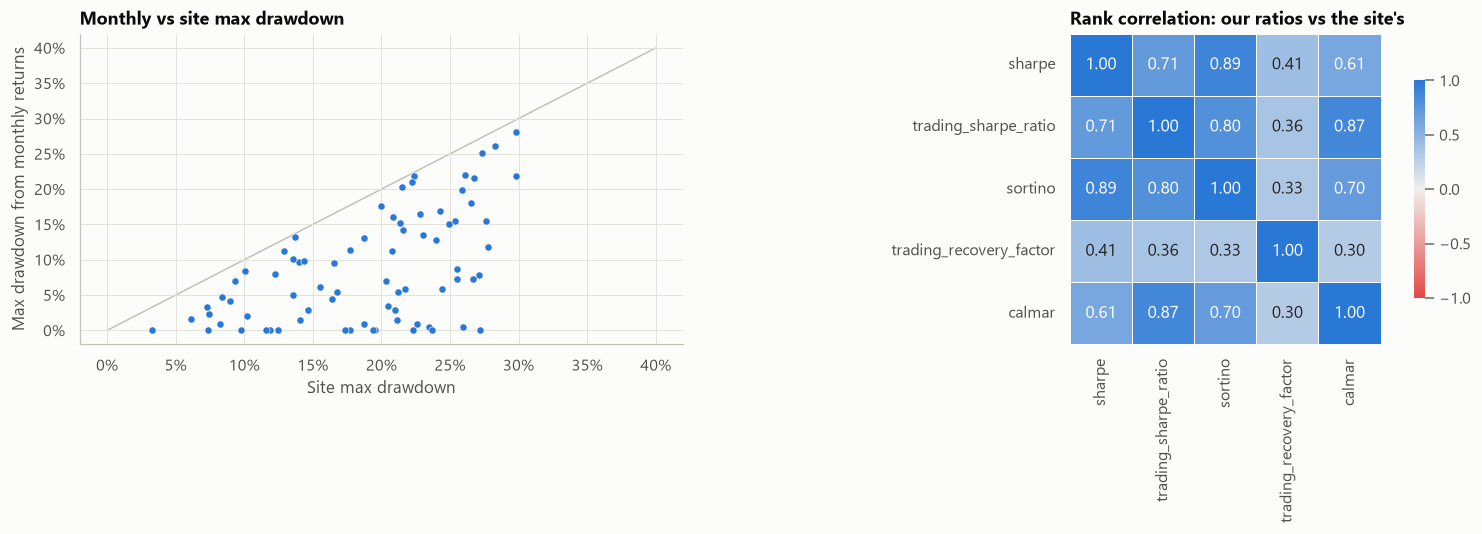

In [7]:
reconstructed = 100 * eligible["total_return"]
close = (reconstructed - eligible["return_total"]).abs() <= np.maximum(1, 0.02 * eligible["return_total"].abs())
print(f"Compounded monthly series matches site return_total (±1pp or 2%): {close.mean():.1%} of eligible leaders")
print(f"Monthly drawdown ≤ site drawdown (+1pp tolerance): {(eligible['monthly_max_drawdown'] <= eligible['max_drawdown'] + 0.01).mean():.1%}")
print(f"Median ratio monthly / site drawdown: {(eligible['monthly_max_drawdown'] / eligible['max_drawdown']).median():.2f}")

dd_plot = eligible.assign(site=100 * eligible["max_drawdown"], monthly=100 * eligible["monthly_max_drawdown"])
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.1]})
sns.scatterplot(data=dd_plot, x="site", y="monthly", color=ps.PRIMARY, s=22, ax=axes[0])
axes[0].plot([0, 40], [0, 40], color=ps.BASELINE, linewidth=1, zorder=0)
axes[0].set_title("Monthly vs site max drawdown")
axes[0].set_xlabel("Site max drawdown")
axes[0].set_ylabel("Max drawdown from monthly returns")
axes[0].xaxis.set_major_formatter(ps.percent_formatter)
axes[0].yaxis.set_major_formatter(ps.percent_formatter)

rank_corr = eligible[["sharpe", "trading_sharpe_ratio", "sortino", "trading_recovery_factor", "calmar"]].rank().corr()
sns.heatmap(rank_corr, cmap=ps.DIVERGING_CMAP, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", square=True,
            linewidths=0.5, linecolor=ps.SURFACE, cbar_kws={"shrink": 0.7}, ax=axes[1])
axes[1].set_title("Rank correlation: our ratios vs the site's")
plt.tight_layout()
plt.show()

In [8]:
mismatch = eligible.loc[~close, ["name", "return_total", "total_return", "age_days", "first_month"]].assign(
    total_return=lambda d: (100 * d["total_return"]).round(2))
print(f"{len(mismatch)} eligible leaders don't reconcile:")
mismatch

4 eligible leaders don't reconcile:


,name,return_total,total_return,age_days,first_month
156,PITAGORA,69.12,16.86,572,2025-02
172,chartlistner,19.03,5.11,582,2025-02
208,4X_CAPITAL,46.46,29.19,584,2025-02
229,Billionaire,85.87,76.56,532,2025-03


**Validation:**
- The compounded monthly series reproduces the site's `return_total` for **94.7%** of eligible leaders. The 4 that don't all started in February-March 2025, which points to a site-side glitch in one shared month rather than a parsing error. CAGR and Calmar use the site's `return_total`, so these 4 are affected only through their monthly-series metrics.
- The monthly drawdown never exceeds the site's drawdown (100%), as it should, but it captures only a **median 41%** of it. More than half of a typical leader's worst loss happens *within* a month or in open positions. That is why the risk side of the score uses the site's max drawdown and leverage, not just monthly data.
- Our Sharpe ranks leaders similarly to the site's (ρ = 0.71). The site's Sharpe tracks our Calmar even more closely (ρ = 0.87), so it is probably computed from daily equity and is drawdown-sensitive. `trading_recovery_factor` barely agrees with anything (ρ ≤ 0.41) and isn't used.

## 5. Composite score

Weights are set **per group** (what the metric measures) and then split within the group, so correlated metrics don't stack up. Risk-adjusted return and risk together carry 60% and raw return only 15%, which reflects the ruin findings in 02. Each metric becomes a percentile rank within the eligible universe (robust to the extreme outliers here), and the score is the weighted average on a 0-100 scale.

In [9]:
WEIGHTS = {
    # Risk-adjusted return (35%)
    "sortino": 0.15, "calmar": 0.10, "psr": 0.10,
    # Return (15%)
    "cagr": 0.15,
    # Risk (25%) - negative weight = lower is better
    "max_drawdown": -0.10, "ulcer_index": -0.05, "lev_p95": -0.10,
    # Consistency (10%)
    "positive_months": 0.10,
    # Trade edge (10%)
    "profit_factor": 0.05, "expectancy_r": 0.05,
    # Track record (5%)
    "age_days": 0.05,
}
assert abs(sum(abs(w) for w in WEIGHTS.values()) - 1) < 1e-9

eligible["score"] = pm.composite_score(eligible, WEIGHTS)
eligible["rank"] = eligible["score"].rank(ascending=False, method="min").astype(int)

DISPLAY = ["rank", "name", "trader_id", "score", "track_record", "style_tier", "primary_asset_class", "age_days", "cagr", "max_drawdown",
           "sortino", "calmar", "psr", "positive_months", "profit_factor", "expectancy_r", "lev_p95", "win_rate", "trades_per_day"]
FORMATS = {"score": "{:.1f}", "cagr": "{:.1%}", "max_drawdown": "{:.1%}", "sortino": "{:.2f}", "calmar": "{:.2f}",
           "psr": "{:.2f}", "positive_months": "{:.0%}", "profit_factor": "{:.2f}", "expectancy_r": "{:.2f}",
           "lev_p95": "{:.1f}", "win_rate": "{:.0%}", "trades_per_day": "{:.2f}"}

top = eligible.sort_values("score", ascending=False).head(TOP_N)
top[DISPLAY].style.format(FORMATS).hide(axis="index")

rank,name,trader_id,score,track_record,style_tier,primary_asset_class,age_days,cagr,max_drawdown,sortino,calmar,psr,positive_months,profit_factor,expectancy_r,lev_p95,win_rate,trades_per_day
1,usd/jpy,10342,85.9,watchlist,<1/day,FX,311,84.2%,11.9%,4683.39,7.10,1.00,100%,3.00,0.66,9.1,67%,0.84
2,LegacyFX,9329,82.8,established,1-5/day,FX,405,127.2%,11.6%,4683.39,10.97,1.00,100%,2.72,0.18,23.1,90%,1.87
3,Golden Prime,11041,76.8,watchlist,1-5/day,Metals,268,172.5%,7.4%,39.07,23.25,1.00,67%,1.94,0.31,11.0,67%,3.22
4,NEPTUNE SHOOTER GOLD ALGO,10574,75.2,watchlist,1-5/day,Metals,184,163.5%,9.7%,4683.39,16.80,0.99,83%,2.10,0.50,40.2,54%,1.05
5,NoPain,10115,74.7,watchlist,1-5/day,FX,241,43.9%,17.7%,4683.39,2.48,1.00,100%,1.99,0.28,8.7,72%,1.43
6,Macro Algo,8735,74.5,established,1-5/day,FX,418,102.9%,21.0%,26.74,4.90,1.00,93%,3.09,0.49,18.4,76%,3.00
7,SuperGold Fase 2,10336,74.3,watchlist,1-5/day,Metals,214,631.9%,17.3%,4683.39,36.49,1.00,86%,1.78,0.28,50.8,63%,2.28
8,Gold-EA,9381,73.4,watchlist,5-10/day,Metals,362,329.3%,23.5%,411.60,14.02,1.00,92%,1.98,0.28,31.8,71%,5.79
9,RSIMED,6832,72.5,established,<1/day,FX,654,43.4%,27.2%,4683.39,1.60,1.00,100%,2.52,0.24,7.2,84%,0.60
10,Kirana GBP Invest,9124,72.4,established,1-5/day,FX,375,54.6%,19.4%,4683.39,2.81,1.00,100%,1.47,0.22,17.3,52%,1.59


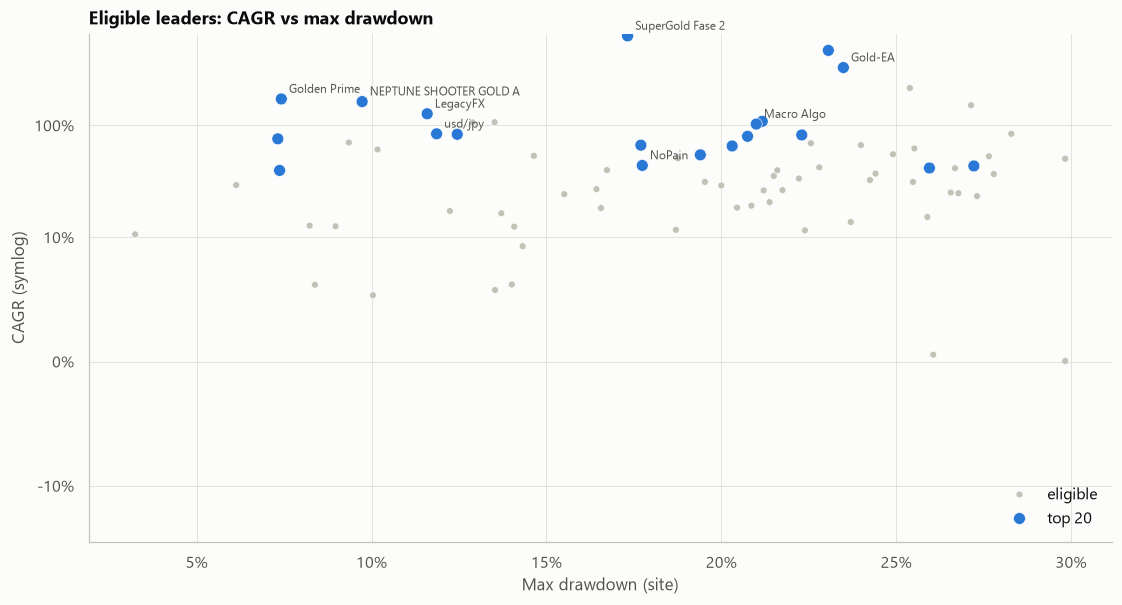

In [10]:
plot_df = eligible.assign(
    group=np.where(eligible.index.isin(top.index), f"top {TOP_N}", "eligible"),
    cagr_pct=100 * eligible["cagr"],
    dd_pct=100 * eligible["max_drawdown"],
)
fig, ax = plt.subplots(figsize=(12, 6))
sns.scatterplot(data=plot_df.sort_values("group"), x="dd_pct", y="cagr_pct", hue="group", size="group",
                sizes={"eligible": 20, f"top {TOP_N}": 60}, palette={"eligible": ps.NEUTRAL, f"top {TOP_N}": ps.PRIMARY}, ax=ax)
for _, row in top.head(8).iterrows():
    ax.annotate(row["name"][:22], (100 * row["max_drawdown"], 100 * row["cagr"]), xytext=(5, 4),
                textcoords="offset points", fontsize=8, color=ps.INK_SECONDARY)
ax.set_yscale("symlog", linthresh=10)
ax.set_title("Eligible leaders: CAGR vs max drawdown")
ax.set_xlabel("Max drawdown (site)")
ax.set_ylabel("CAGR (symlog)")
ax.xaxis.set_major_formatter(ps.percent_formatter)
ax.yaxis.set_major_formatter(ps.percent_formatter)
ax.legend(title="", loc="lower right")
plt.show()

**Insights:**
- **76 leaders** are eligible (4.2% of those with a track record): **50 established** (1 year+) and **26 on the watchlist** (6-12 months). The activity rule from 02 (a non-zero return in the last 3 complete months) is the biggest cut after ruin, from 903 to 531. The top-20 cut-off sits at a score of 65 out of 100.
- The top 20 are **12 FX and 8 gold** strategies, even though gold leaders outnumber FX leaders 2:1 on the platform. Gold traders mostly fail the risk filters before scoring even starts (02 §8).
- **10 of the top 20 are watchlist leaders**, including the #1 (usd/jpy). Young records score well because a short, smooth run has no bad month yet; that is exactly why they aren't copied until they've lasted a year.
- The top 20 earn more without taking more risk: median CAGR is **83%** compared with 40% for the eligible universe, at a similar median max drawdown (19% vs 21%) and lower p95 leverage (17x vs 21x).
- No eligible leader trades 10-15 times a day, and only 1 trades 15+ times a day: high-frequency strategies almost never survive the filters.
- **10 of the top 20 have no losing complete month.** Their site-reported drawdowns (7-27%) show losses that happen *within* months or sit in open positions, which is typical of grid and averaging strategies. Check the site's equity curve and open-position history before copying any of them.

### Top candidates per trading style

A 10-trades-a-day bot and a swing trader are different products, so the best leaders are also shown per trading-style tier. The scores come from the single eligible universe, so they are comparable across tiers.

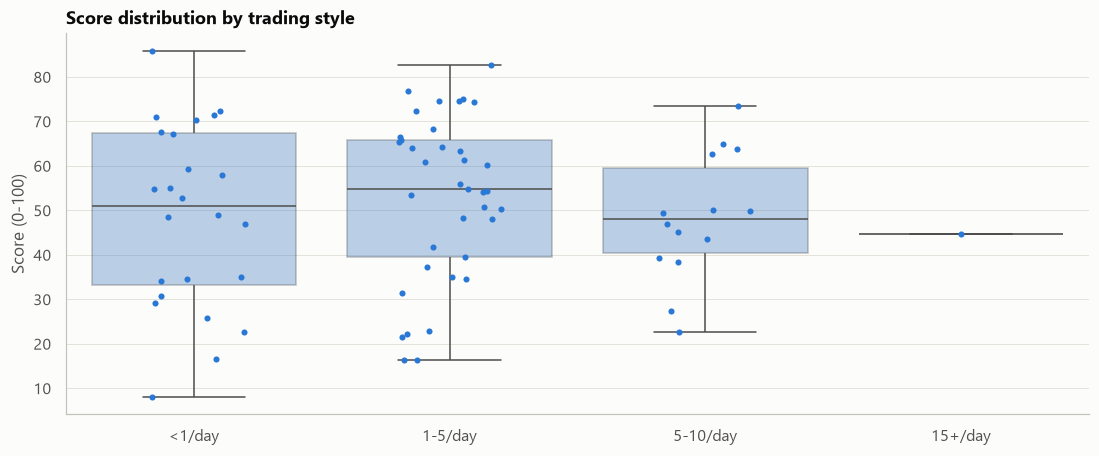

style_tier
<1/day       24
1-5/day      37
5-10/day     14
10-15/day     0
15+/day       1


rank,name,trader_id,score,track_record,style_tier,primary_asset_class,age_days,cagr,max_drawdown,sortino,calmar,psr,positive_months,profit_factor,expectancy_r,lev_p95,win_rate,trades_per_day
1,usd/jpy,10342,85.9,watchlist,<1/day,FX,311,84.2%,11.9%,4683.39,7.10,1.00,100%,3.00,0.66,9.1,67%,0.84
9,RSIMED,6832,72.5,established,<1/day,FX,654,43.4%,27.2%,4683.39,1.60,1.00,100%,2.52,0.24,7.2,84%,0.60
11,335 Academy (Mini),6701,71.4,established,<1/day,Metals,661,108.9%,21.2%,69.24,5.14,1.00,95%,2.34,0.08,38.5,94%,0.79
12,Gediyafx ea,10624,71.1,established,<1/day,Metals,469,469.1%,23.1%,20.40,20.34,1.00,92%,2.26,0.29,49.6,77%,0.50
13,Quantum King FX Signals,11100,70.2,watchlist,<1/day,FX,184,39.6%,7.4%,4683.39,5.38,0.99,67%,2.53,0.44,12.3,71%,0.57
2,LegacyFX,9329,82.8,established,1-5/day,FX,405,127.2%,11.6%,4683.39,10.97,1.00,100%,2.72,0.18,23.1,90%,1.87
3,Golden Prime,11041,76.8,watchlist,1-5/day,Metals,268,172.5%,7.4%,39.07,23.25,1.00,67%,1.94,0.31,11.0,67%,3.22
4,NEPTUNE SHOOTER GOLD ALGO,10574,75.2,watchlist,1-5/day,Metals,184,163.5%,9.7%,4683.39,16.80,0.99,83%,2.10,0.50,40.2,54%,1.05
5,NoPain,10115,74.7,watchlist,1-5/day,FX,241,43.9%,17.7%,4683.39,2.48,1.00,100%,1.99,0.28,8.7,72%,1.43
6,Macro Algo,8735,74.5,established,1-5/day,FX,418,102.9%,21.0%,26.74,4.90,1.00,93%,3.09,0.49,18.4,76%,3.00


In [11]:
fig, ax = plt.subplots(figsize=(12, 4.5))
tiers_present = [t for t in STYLE_LABELS if (eligible["style_tier"] == t).any()]
sns.boxplot(data=eligible, x="style_tier", y="score", order=tiers_present, color=ps.SERIES[0],
            boxprops={"alpha": 0.35}, showfliers=False, ax=ax)
sns.stripplot(data=eligible, x="style_tier", y="score", order=tiers_present, color=ps.PRIMARY, size=4, jitter=0.2, ax=ax)
ax.set_title("Score distribution by trading style")
ax.set_xlabel("")
ax.set_ylabel("Score (0-100)")
plt.show()

per_tier = (eligible.sort_values("score", ascending=False)
            .groupby("style_tier", observed=True).head(5)
            .sort_values(["style_tier", "score"], ascending=[True, False]))
print(eligible["style_tier"].value_counts().reindex(STYLE_LABELS).to_string())
per_tier[DISPLAY].style.format(FORMATS).hide(axis="index")

## 6. Robustness

### Sensitivity to the weights

A shortlist that changes completely when a weight moves a little is not a finding. The top 20 is recomputed under alternative weighting schemes and compared with the base case (overlap of the top-20 sets, and rank correlation over the whole eligible universe).

Leaders in the top 20 under every scheme: 11


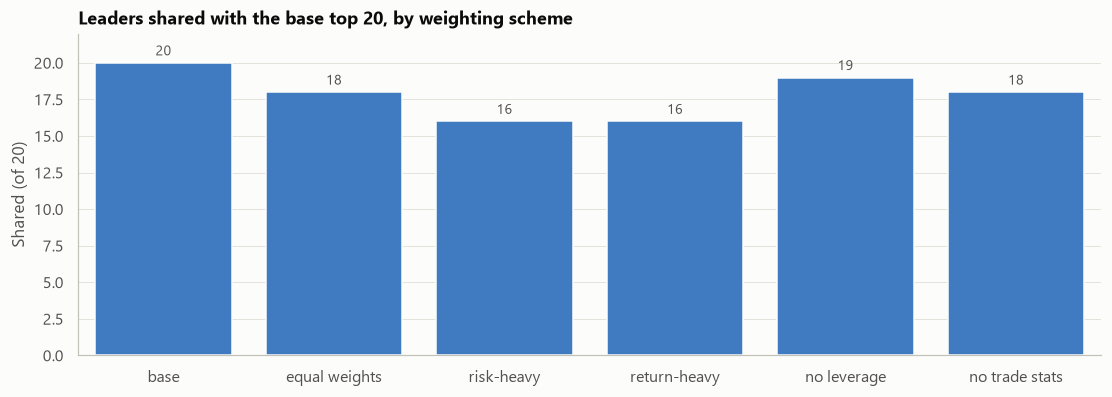

,scheme,shared_in_top20,rank_corr_vs_base
0,base,20,1.00
1,equal weights,18,0.98
2,risk-heavy,16,0.96
3,return-heavy,16,0.90
4,no leverage,19,0.99
5,no trade stats,18,0.99


In [12]:
SCHEMES = {
    "base": WEIGHTS,
    "equal weights": {k: (1 if w > 0 else -1) / len(WEIGHTS) for k, w in WEIGHTS.items()},
    "risk-heavy": {"sortino": 0.10, "calmar": 0.15, "psr": 0.05, "cagr": 0.05, "max_drawdown": -0.20,
                   "ulcer_index": -0.10, "lev_p95": -0.15, "positive_months": 0.10, "profit_factor": 0.05, "age_days": 0.05},
    "return-heavy": {"sortino": 0.15, "calmar": 0.10, "psr": 0.05, "cagr": 0.40, "max_drawdown": -0.10,
                     "lev_p95": -0.05, "positive_months": 0.05, "profit_factor": 0.05, "expectancy_r": 0.05},
    "no leverage": {k: w for k, w in WEIGHTS.items() if k != "lev_p95"},
    "no trade stats": {k: w for k, w in WEIGHTS.items() if k not in ("profit_factor", "expectancy_r")},
}
base_top = set(top.index)
rows = []
for name, weights in SCHEMES.items():
    s = pm.composite_score(eligible, weights)
    alt_top = set(s.nlargest(TOP_N).index)
    rows.append((name, len(alt_top & base_top), s.rank().corr(eligible["score"].rank())))
    eligible[f"score_{name}"] = s
sensitivity = pd.DataFrame(rows, columns=["scheme", "shared_in_top20", "rank_corr_vs_base"]).round(2)

# Leaders in the top 20 under every scheme are the robust core.
eligible["robust_core"] = pd.concat([eligible[f"score_{n}"].rank(ascending=False) <= TOP_N for n in SCHEMES], axis=1).all(axis=1)
print(f"Leaders in the top {TOP_N} under every scheme: {eligible['robust_core'].sum()}")

fig, ax = plt.subplots(figsize=(12, 3.8))
sns.barplot(data=sensitivity, x="scheme", y="shared_in_top20", color=ps.PRIMARY, ax=ax)
ps.label_bars(ax)
ax.set_ylim(0, TOP_N + 2)
ax.set_title(f"Leaders shared with the base top {TOP_N}, by weighting scheme")
ax.set_xlabel("")
ax.set_ylabel(f"Shared (of {TOP_N})")
plt.show()
sensitivity

### Pseudo out-of-sample test

Does a high score predict anything? The return-based part of the score is recomputed using **only the months before a cut-off**, and then compared with the compounded return over the **following 3 months**. The drawdown has to come from the monthly series here (the site's figure includes the future), and leverage and trade stats are left out for the same reason.

Caveat: the dataset only contains leaders still listed at the snapshot, so leaders who closed their accounts are missing (survivorship). Ruined leaders are still listed, so they are included.

Metrics on months before 2026-06, forward window 2026-06 to 2026-08, 168 leaders
Spearman(score, forward return) = 0.24


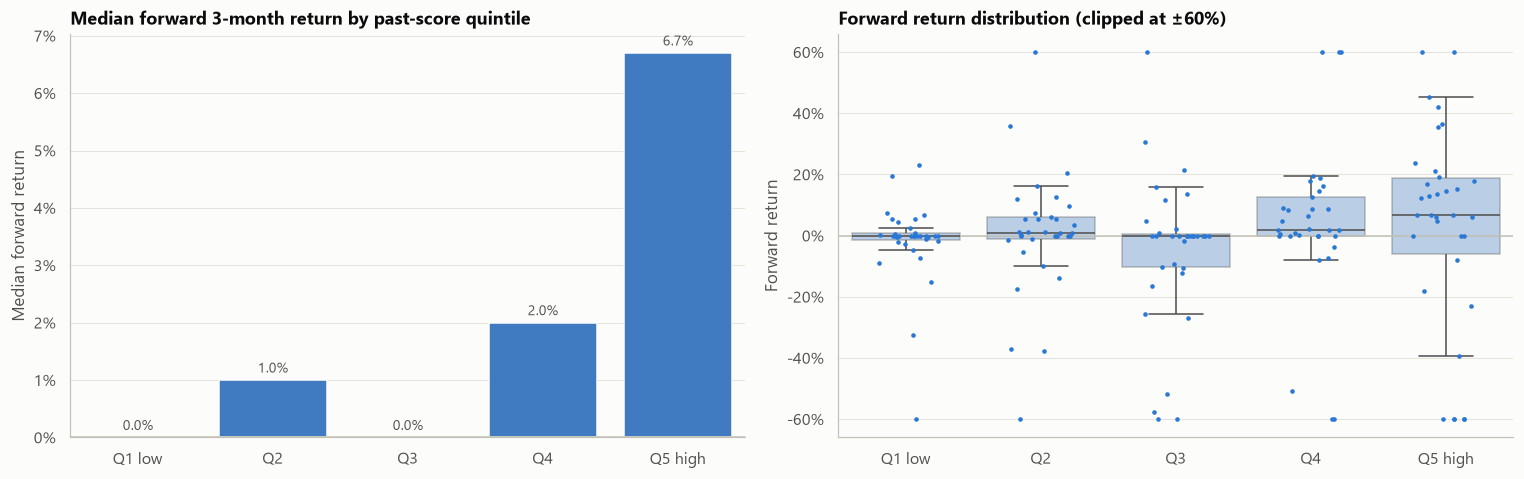

,leaders,median_forward,mean_forward,positive_pct,big_loss_pct
quintile,,,,,
Q1 low,34,0.0,-3.0,32.4,5.9
Q2,33,1.0,-0.2,57.6,9.1
Q3,34,0.0,-6.6,26.5,11.8
Q4,33,2.0,7.2,66.7,9.1
Q5 high,34,6.7,1.0,64.7,17.6


In [13]:
FORWARD = 3                  # forward test window, in months
CUTOFF = SNAPSHOT - FORWARD  # metrics use months < CUTOFF; the test uses the FORWARD complete months after it
OOS_WEIGHTS = {"sortino": 0.25, "calmar_monthly": 0.20, "psr": 0.15, "cagr_monthly": 0.15,
               "monthly_max_drawdown": -0.15, "positive_months": 0.10}

rows = []
for idx, returns in df["returns_complete"].items():
    past = returns[returns.index < CUTOFF]
    future = returns[(returns.index >= CUTOFF) & (returns.index < CUTOFF + FORWARD)]
    if len(past) < MIN_COMPLETE_MONTHS or len(future) < FORWARD or df.at[idx, "closed_trades"] < MIN_CLOSED_TRADES:
        continue
    past_dd = pm.max_drawdown(past)
    growth = pm.cagr(pm.compounded_return(past), len(past) * 30.44)
    rows.append({
        "idx": idx, "past_total": pm.compounded_return(past),
        "monthly_max_drawdown": past_dd, "sortino": pm.sortino_ratio(past), "psr": pm.probabilistic_sharpe_ratio(past),
        "cagr_monthly": growth, "calmar_monthly": pm.calmar_ratio(growth, past_dd),
        "positive_months": pm.positive_period_share(past), "forward_return": pm.compounded_return(future),
    })
oos = pd.DataFrame(rows).set_index("idx")
# Same eligibility as the live screen, measured on past data only.
oos = oos[(oos["past_total"] > 0) & (oos["monthly_max_drawdown"] <= MAX_DRAWDOWN_LIMIT / 100)]
oos["sortino"] = oos["sortino"].fillna(oos["sortino"].max())  # no losing month -> best, as in §4
oos["score"] = pm.composite_score(oos, OOS_WEIGHTS)
oos["quintile"] = pd.qcut(oos["score"].rank(method="first"), 5, labels=["Q1 low", "Q2", "Q3", "Q4", "Q5 high"])
oos["forward_pct"] = 100 * oos["forward_return"]

oos_summary = oos.groupby("quintile", observed=True)["forward_return"].agg(
    leaders="size",
    median_forward=lambda s: 100 * s.median(),
    mean_forward=lambda s: 100 * s.mean(),
    positive_pct=lambda s: 100 * (s > 0).mean(),
    big_loss_pct=lambda s: 100 * (s <= -0.30).mean(),
).round(1)
print(f"Metrics on months before {CUTOFF}, forward window {CUTOFF} to {CUTOFF + FORWARD - 1}, {len(oos)} leaders")
print(f"Spearman(score, forward return) = {oos['score'].rank().corr(oos['forward_return'].rank()):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(x=oos_summary.index.astype(str), y=oos_summary["median_forward"], color=ps.PRIMARY, ax=axes[0])
ps.label_bars(axes[0], fmt="{:.1f}%")
axes[0].axhline(0, color=ps.BASELINE, linewidth=1)
axes[0].set_title(f"Median forward {FORWARD}-month return by past-score quintile")
axes[0].set_xlabel("")
axes[0].set_ylabel("Median forward return")
axes[0].yaxis.set_major_formatter(ps.percent_formatter)
sns.boxplot(data=oos, x="quintile", y=oos["forward_pct"].clip(-60, 60), color=ps.SERIES[0],
            boxprops={"alpha": 0.35}, showfliers=False, ax=axes[1])
sns.stripplot(data=oos, x="quintile", y=oos["forward_pct"].clip(-60, 60), color=ps.PRIMARY, size=3, jitter=0.25, ax=axes[1])
axes[1].axhline(0, color=ps.BASELINE, linewidth=1)
axes[1].set_title("Forward return distribution (clipped at ±60%)")
axes[1].set_xlabel("")
axes[1].set_ylabel("Forward return")
axes[1].yaxis.set_major_formatter(ps.percent_formatter)
plt.tight_layout()
plt.show()
oos_summary

**Weight sensitivity:** the ranking as a whole is stable: rank correlation with the base case is ≥ 0.90 under every alternative scheme. The exact top 20 is less stable. Dropping leverage keeps 19 of the 20, equal weights and dropping trade stats keep 18, and the risk-heavy and return-heavy extremes keep 16 each. **11 leaders stay in the top 20 under every scheme** (`robust_core` in the export): 5 established (LegacyFX, Macro Algo, Kirana GBP Invest, 335 Academy (Mini), ENZONE - IKIGAI) and 6 on the watchlist.

**Pseudo out-of-sample:** scoring on data up to May 2026 and checking June-August 2026 (168 leaders):
- The score has **modest predictive power**: Spearman ρ = 0.24 with the forward return. The top quintile returned a median **+6.7%** over 3 months with 65% positive, compared with a median of 0.0% and only 32% positive for the bottom quintile.
- It does **not** protect against tail losses: 18% of the top quintile lost 30% or more in those 3 months, more than the bottom quintile (6%), which pulls the top quintile's *mean* down to +1.0%. A high score improves the typical outcome, not the worst one. Spread capital across several leaders, use the copy platform's stop-loss / max-drawdown settings, and size each copy small.
- This is one 3-month window. Re-run it on each new scrape (see the persistence idea in 02 §13) before trusting the score more than this.

## 7. Shortlist

### Equity curves of the top 10 established leaders

Only established leaders (1 year+ of history) are candidates to copy now, so the shortlist is drawn from them; younger leaders are covered by the watchlist in §8.

Compounded monthly equity, indexed to 100 just before each leader's first month (complete months plus the in-progress snapshot month). The panels share a time axis and a log scale, so slopes are comparable.

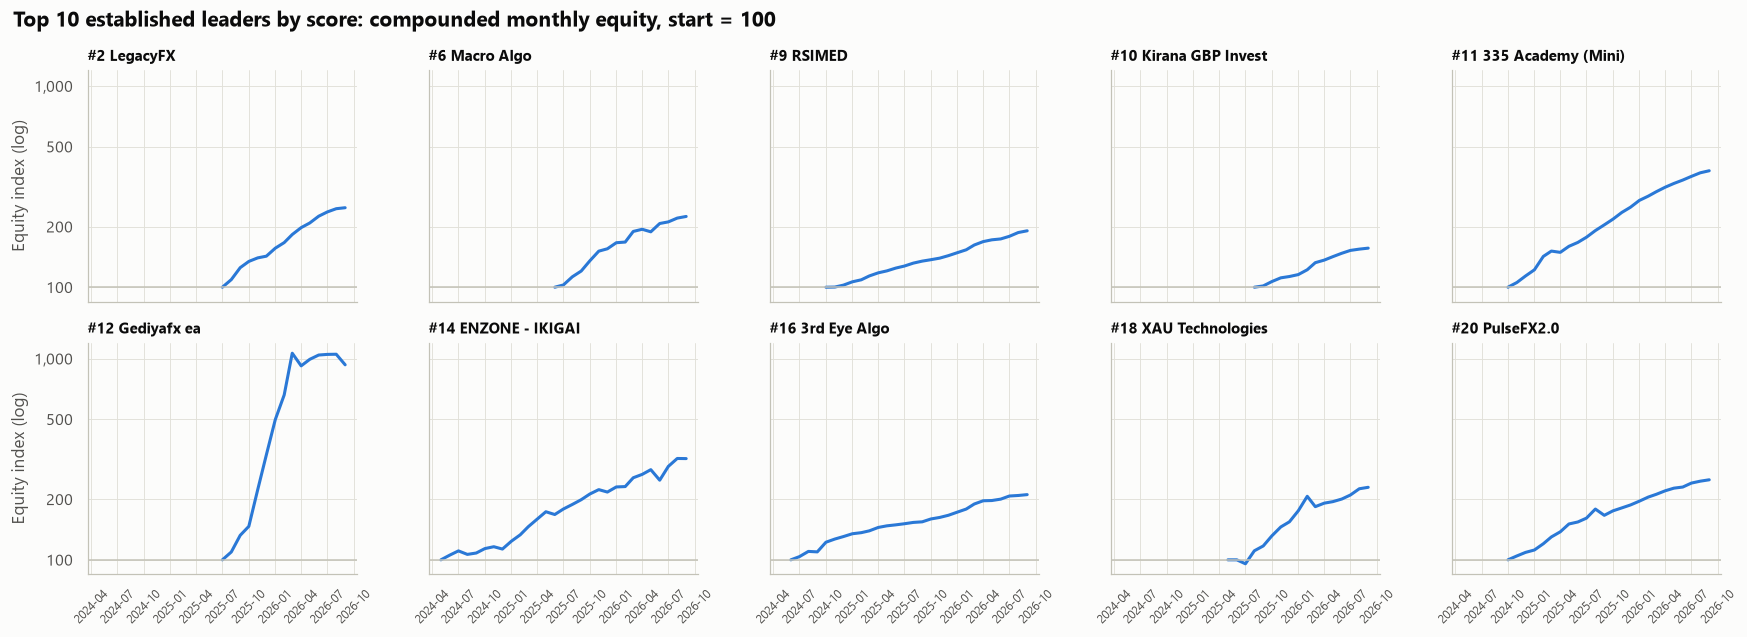

In [14]:
def plot_equity_curves(leaders: pd.DataFrame, title: str) -> None:
    """Small multiples of compounded monthly equity, indexed to 100 before each leader's first month."""
    curves = []
    for _, row in leaders.iterrows():
        returns = row["monthly_returns"]
        # Anchor at 100 the month before the first return, so the first month's gain is visible.
        curve = 100 * pd.concat([pd.Series([1.0], index=[returns.index.min() - 1]), pm.equity_curve(returns)])
        curves.append(pd.DataFrame({"month": curve.index.to_timestamp(), "equity": curve.values,
                                    "leader": f"#{row['rank']} {row['name'][:20]}"}))
    grid = sns.relplot(data=pd.concat(curves, ignore_index=True), x="month", y="equity", col="leader", col_wrap=5,
                       kind="line", color=ps.PRIMARY, height=2.8, aspect=1.15, facet_kws={"sharey": True})
    grid.set(yscale="log")
    # Plain numbers on the log axis: curves spanning less than a decade otherwise get "4×10²" minor labels.
    grid.axes.flat[0].yaxis.set_major_locator(mticker.LogLocator(subs=(1, 2, 5)))
    grid.axes.flat[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    grid.axes.flat[0].yaxis.set_minor_formatter(mticker.NullFormatter())
    grid.set_titles("{col_name}", size=10, fontweight="bold")
    grid.set_axis_labels("", "Equity index (log)")
    for ax in grid.axes.flat:
        ax.axhline(100, color=ps.BASELINE, linewidth=1)
        ax.tick_params(axis="x", labelrotation=45, labelsize=8)
    grid.figure.suptitle(title, x=0.01, ha="left", fontweight="bold", y=1.03)
    plt.show()


established = eligible[eligible["track_record"] == "established"].sort_values("score", ascending=False)
top10 = established.head(10)
plot_equity_curves(top10, "Top 10 established leaders by score: compounded monthly equity, start = 100")

### Correlation-aware pick

02 showed that most leaders trade gold, so copying the top 5 could mean copying the same bet five times. Starting from the highest-scoring established leader, walk down the ranking and add a leader only if its monthly returns correlate below `MAX_PAIR_CORR` with every leader already picked. Correlation is computed over overlapping months, with at least 6 required. Negative correlation is welcome.

In [15]:
MAX_PAIR_CORR = 0.5
SHORTLIST_SIZE = 5
MIN_OVERLAP = 6

candidates = established.head(40)
returns_wide = pd.DataFrame({idx: r for idx, r in candidates["returns_complete"].items()})
pair_corr = returns_wide.corr(min_periods=MIN_OVERLAP)

picked = []
for idx in candidates.index:
    corr_to_picked = pair_corr.loc[idx, picked].dropna() if picked else pd.Series(dtype=float)
    # Signed, not abs(): a negatively correlated leader is exactly what diversification wants.
    if (corr_to_picked < MAX_PAIR_CORR).all():
        picked.append(idx)
    if len(picked) == SHORTLIST_SIZE:
        break

shortlist = eligible.loc[picked]
off_diagonal = pair_corr.loc[top10.index, top10.index].where(~np.eye(len(top10), dtype=bool)).stack()
print(f"Median pairwise correlation among the top 10 established leaders: {off_diagonal.median():.2f}")
shortlist[DISPLAY + ["robust_core"]].style.format(FORMATS).hide(axis="index")

Median pairwise correlation among the top 10 established leaders: 0.10


rank,name,trader_id,score,track_record,style_tier,primary_asset_class,age_days,cagr,max_drawdown,sortino,calmar,psr,positive_months,profit_factor,expectancy_r,lev_p95,win_rate,trades_per_day,robust_core
2,LegacyFX,9329,82.8,established,1-5/day,FX,405,127.2%,11.6%,4683.39,10.97,1.00,100%,2.72,0.18,23.1,90%,1.87,True
6,Macro Algo,8735,74.5,established,1-5/day,FX,418,102.9%,21.0%,26.74,4.90,1.00,93%,3.09,0.49,18.4,76%,3.00,True
9,RSIMED,6832,72.5,established,<1/day,FX,654,43.4%,27.2%,4683.39,1.60,1.00,100%,2.52,0.24,7.2,84%,0.60,False
10,Kirana GBP Invest,9124,72.4,established,1-5/day,FX,375,54.6%,19.4%,4683.39,2.81,1.00,100%,1.47,0.22,17.3,52%,1.59,True
11,335 Academy (Mini),6701,71.4,established,<1/day,Metals,661,108.9%,21.2%,69.24,5.14,1.00,95%,2.34,0.08,38.5,94%,0.79,True


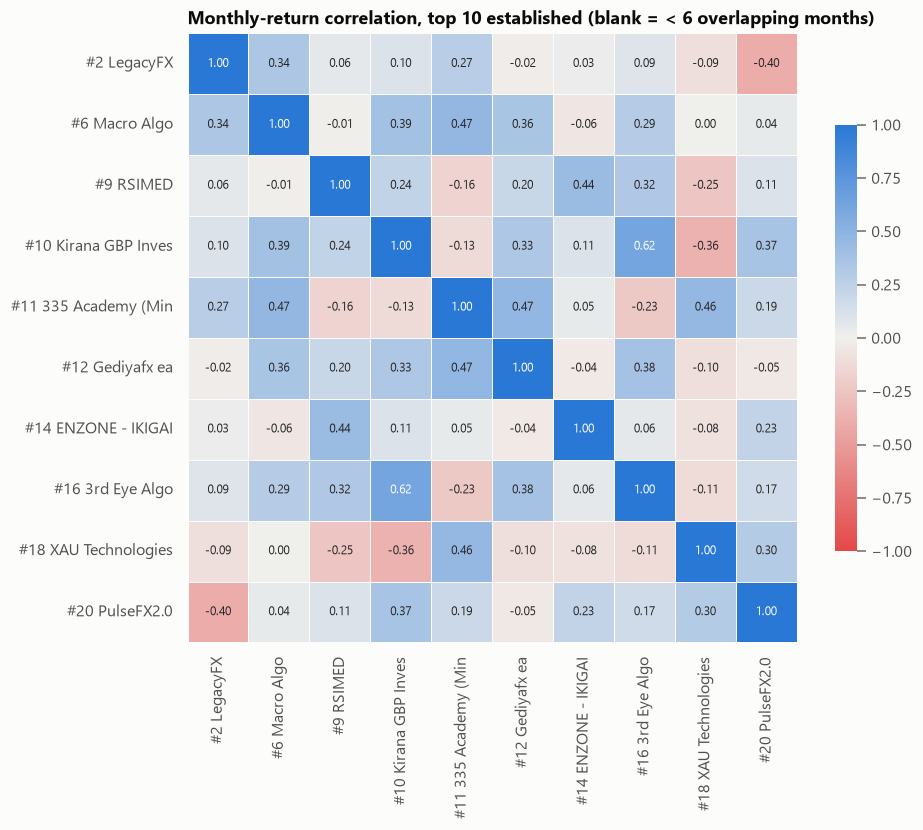

In [16]:
labels = [f"#{eligible.at[i, 'rank']} {eligible.at[i, 'name'][:16]}" for i in top10.index]
matrix = pair_corr.loc[top10.index, top10.index]
matrix.index = matrix.columns = labels

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(matrix, cmap=ps.DIVERGING_CMAP, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"fontsize": 8}, square=True, linewidths=0.5, linecolor=ps.SURFACE,
            cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Monthly-return correlation, top 10 established (blank = < 6 overlapping months)")
plt.tight_layout()
plt.show()

**Insights:**
- Among established leaders, the equity curves separate **steady compounders** (335 Academy (Mini), 3rd Eye Algo, RSIMED, LegacyFX, Kirana GBP Invest, PulseFX2.0: smooth, nearly straight lines on a log scale) from **burst profiles** (Gediyafx ea: about 10× in 8 months, then flat and slightly down). Burst profiles score well on CAGR and Calmar but are the least likely to repeat. Prefer the steady ones. ENZONE - IKIGAI and XAU Technologies have had dips worth watching.
- Correlation among the top 10 established leaders is low (median 0.10). The closest pair is Kirana GBP Invest and 3rd Eye Algo (0.62); LegacyFX moves against PulseFX2.0 (−0.40), which is useful diversification.
- The correlation-aware pick gives **LegacyFX, Macro Algo, RSIMED, Kirana GBP Invest and 335 Academy (Mini)** (4 FX + 1 gold, all with p95 leverage ≤ 39x). All but RSIMED are in the robust core, and all five are steady compounders.
- The correlations are often computed on about a year of overlapping months, so they are noisy. Treat them as a guard against obvious duplicates, not as precise numbers.

## 8. Watchlist: 6-12 month track records

Leaders with 180-364 days of history that pass every filter. They're scored on the same scale as everyone else, but they aren't copy candidates yet: their record is too short to tell skill from a lucky run. The plan is to save them as a dated **baseline**, scrape again in `RECHECK_AFTER_MONTHS` months, and check how they did in between (§9).

### Why a year: forward results by track-record length

The evidence behind the 1-year line. At every monthly cut-off from 15 to 3 months before the snapshot, take the leaders that were profitable, active and had at least 6 months of history at that point, and measure their compounded return over the following 3 months. "Stopped" means no further returns (the account went quiet or closed). The same leader appears at several cut-offs, so the observations overlap and the real sample is smaller than the count suggests.

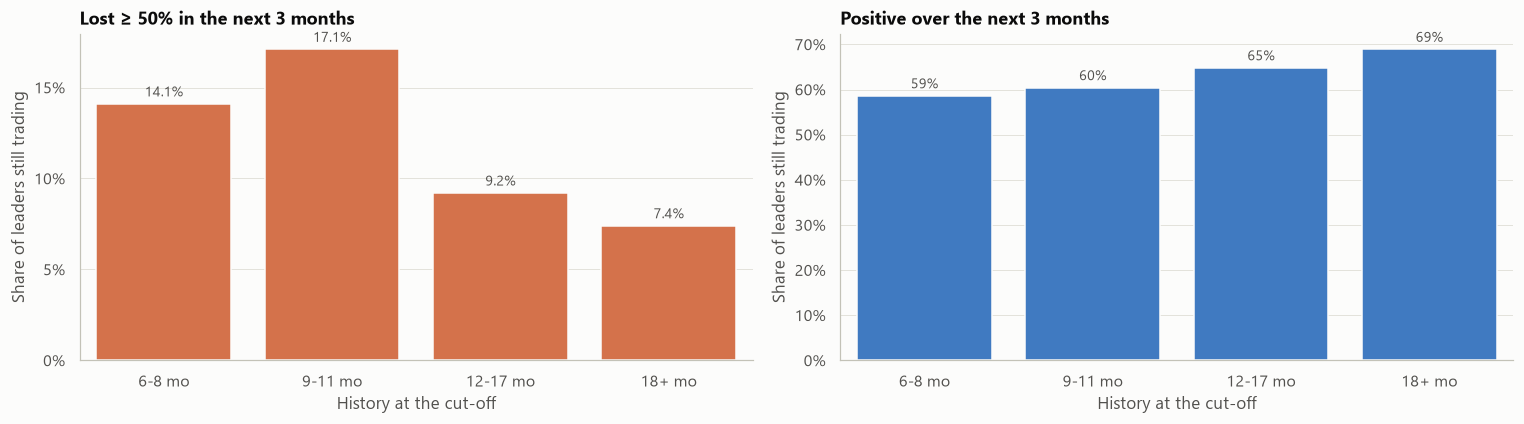

,observations,stopped_pct,median_forward,positive_pct,lost_half_pct
history,,,,,
6-8 mo,629,12.1,3.4,58.6,14.1
9-11 mo,460,12.2,4.4,60.4,17.1
12-17 mo,515,6.8,4.5,64.8,9.2
18+ mo,706,6.2,5.2,68.9,7.4


In [17]:
HISTORY_LABELS = ["6-8 mo", "9-11 mo", "12-17 mo", "18+ mo"]
records = []
for cutoff in pd.period_range(SNAPSHOT - 15, SNAPSHOT - FORWARD, freq="M"):
    for idx, returns in df.loc[df["closed_trades"] >= MIN_CLOSED_TRADES, "returns_complete"].items():
        past = returns[returns.index < cutoff]
        future = returns[(returns.index >= cutoff) & (returns.index < cutoff + FORWARD)]
        # Same activity rule as is_active in 02: a non-zero return in one of the 3 months before the cut-off.
        active = (past[past.index >= cutoff - 3] != 0).any()
        if len(past) < MIN_COMPLETE_MONTHS or not active or pm.compounded_return(past) <= 0:
            continue
        stopped = len(future) < FORWARD or (future == 0).all()
        records.append({"months": len(past), "stopped": stopped,
                        "forward": np.nan if stopped else pm.compounded_return(future)})
history = pd.DataFrame(records)
history["history"] = pd.cut(history["months"], [6, 9, 12, 18, np.inf], right=False, labels=HISTORY_LABELS)

by_history = history.groupby("history", observed=True).agg(
    observations=("months", "size"),
    stopped_pct=("stopped", lambda s: 100 * s.mean()),
    median_forward=("forward", lambda s: 100 * s.median()),
    positive_pct=("forward", lambda s: 100 * (s.dropna() > 0).mean()),
    lost_half_pct=("forward", lambda s: 100 * (s.dropna() <= -0.5).mean()),
).round(1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(x=by_history.index.astype(str), y=by_history["lost_half_pct"], color=ps.HIGHLIGHT, ax=axes[0])
ps.label_bars(axes[0], fmt="{:.1f}%")
axes[0].set_title(f"Lost ≥ 50% in the next {FORWARD} months")
axes[0].set_ylabel("Share of leaders still trading")
axes[0].yaxis.set_major_locator(mticker.MultipleLocator(5))
sns.barplot(x=by_history.index.astype(str), y=by_history["positive_pct"], color=ps.PRIMARY, ax=axes[1])
ps.label_bars(axes[1], fmt="{:.0f}%")
axes[1].set_title(f"Positive over the next {FORWARD} months")
axes[1].set_ylabel("Share of leaders still trading")
for ax in axes:
    ax.set_xlabel("History at the cut-off")
    ax.yaxis.set_major_formatter(ps.percent_formatter)
plt.tight_layout()
plt.show()
by_history

**Insights:**
- Leaders with **6-11 months** of history were about **twice as likely to lose half their money** in the next 3 months (14.1-17.1%) as those with a year or more (7.4-9.2%), and twice as many stopped trading (12% vs 6-7%).
- The longer record doesn't cost return: the median 3-month return is similar or slightly better (+3.4% at 6-8 months, +5.2% at 18+ months), and the share of positive outcomes rises from 59% to 69%.
- So six profitable months isn't yet evidence of a robust strategy. A year is where the blow-up risk clearly drops, which is the line used for copying now.

### The watchlist

Watchlist leaders ranked by score, with the month in which each one reaches a full year of history. Their equity curves follow, for the top 10.

In [18]:
watchlist = eligible[eligible["track_record"] == "watchlist"].sort_values("score", ascending=False).copy()
watchlist["established_from"] = [
    (scraped + pd.Timedelta(days=COPY_MIN_AGE_DAYS - age)).to_period("M")
    for scraped, age in zip(watchlist["scraped_at"], watchlist["age_days"])
]
print(f"{len(watchlist)} watchlist leaders ({(watchlist['rank'] <= TOP_N).sum()} of them in the overall top {TOP_N})")
watchlist[DISPLAY + ["established_from"]].style.format(FORMATS).hide(axis="index")

26 watchlist leaders (10 of them in the overall top 20)


rank,name,trader_id,score,track_record,style_tier,primary_asset_class,age_days,cagr,max_drawdown,sortino,calmar,psr,positive_months,profit_factor,expectancy_r,lev_p95,win_rate,trades_per_day,established_from
1,usd/jpy,10342,85.9,watchlist,<1/day,FX,311,84.2%,11.9%,4683.39,7.10,1.00,100%,3.00,0.66,9.1,67%,0.84,2026-11
3,Golden Prime,11041,76.8,watchlist,1-5/day,Metals,268,172.5%,7.4%,39.07,23.25,1.00,67%,1.94,0.31,11.0,67%,3.22,2026-12
4,NEPTUNE SHOOTER GOLD ALGO,10574,75.2,watchlist,1-5/day,Metals,184,163.5%,9.7%,4683.39,16.80,0.99,83%,2.10,0.50,40.2,54%,1.05,2027-03
5,NoPain,10115,74.7,watchlist,1-5/day,FX,241,43.9%,17.7%,4683.39,2.48,1.00,100%,1.99,0.28,8.7,72%,1.43,2027-01
7,SuperGold Fase 2,10336,74.3,watchlist,1-5/day,Metals,214,631.9%,17.3%,4683.39,36.49,1.00,86%,1.78,0.28,50.8,63%,2.28,2027-02
8,Gold-EA,9381,73.4,watchlist,5-10/day,Metals,362,329.3%,23.5%,411.60,14.02,1.00,92%,1.98,0.28,31.8,71%,5.79,2026-09
13,Quantum King FX Signals,11100,70.2,watchlist,<1/day,FX,184,39.6%,7.4%,4683.39,5.38,0.99,67%,2.53,0.44,12.3,71%,0.57,2027-03
15,Quantum Athena FX Signals,11351,67.7,watchlist,<1/day,Metals,184,83.4%,12.4%,4683.39,6.70,0.99,50%,3.84,0.56,56.3,80%,0.88,2027-03
17,Multipairs 3,10725,66.5,watchlist,1-5/day,FX,230,82.3%,22.3%,4683.39,3.69,1.00,62%,3.03,0.34,23.6,83%,3.55,2027-01
19,FxBro Sync,10460,65.4,watchlist,1-5/day,FX,199,76.0%,7.3%,13.61,10.38,0.89,83%,1.71,0.19,17.2,73%,1.72,2027-02


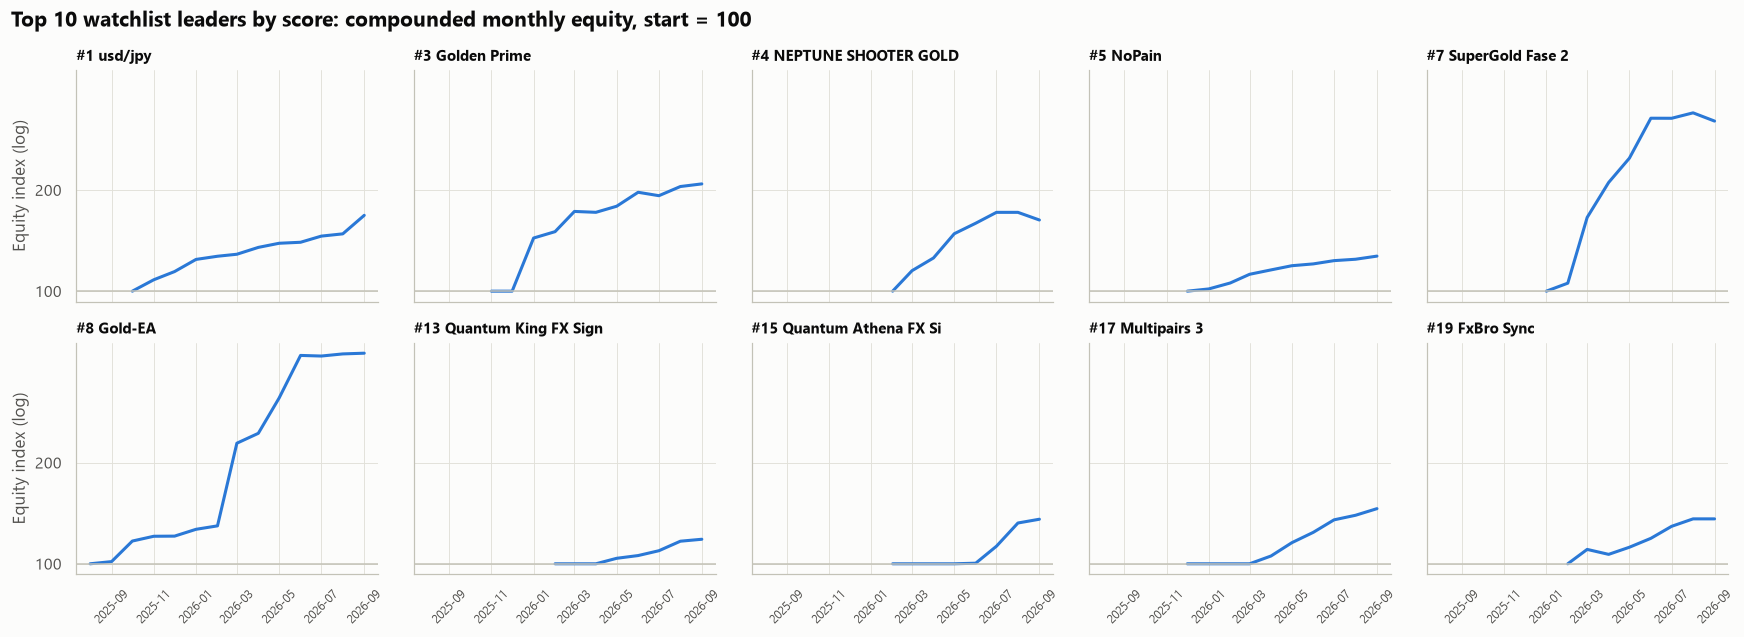

In [19]:
plot_equity_curves(watchlist.head(10), "Top 10 watchlist leaders by score: compounded monthly equity, start = 100")

**Insights:**
- The 26 watchlist leaders score higher on average than established ones (median 61 vs 49) and show a higher median CAGR (65% vs 30%) at a lower drawdown (17% vs 21%). That is the short-record effect: fewer months means fewer chances to have hit a bad one. The re-check will show how much of it holds.
- They lean slightly towards **gold** (13 of 26, against 11 FX), unlike the established shortlist.
- The most promising are the 6 in the robust core: **usd/jpy, Golden Prime, NEPTUNE SHOOTER GOLD ALGO, NoPain, SuperGold Fase 2 and Gold-EA**. usd/jpy and NoPain are the steadiest curves; SuperGold Fase 2 and Gold-EA are burst profiles that already flattened.
- Treat with suspicion: 6 have **p95 leverage above 100x** (for example CopyTradingPRO_Hedge, AlphaTrend - II, 777018 TPFX Stream Deck EA), and 777018 TPFX Stream Deck EA also has a profit factor below 1.
- Several reach a year within weeks of the snapshot (Gold-EA and barrel500 in September; Pulse FX, CopyTradingPRO_Hedge, AlphaTrend - II and 777018 TPFX Stream Deck EA in October). They will already count as established at the next scrape, but the re-check still asks for a profit since the baseline before calling them copy candidates.

### Save the baseline

The watchlist is saved as `analysis/data/fpmarkets_watchlist_<snapshot month>.pkl` (plus a CSV copy without the monthly series), with each leader's score, rank, returns and drawdown at this snapshot. Re-running this notebook on the same scrape overwrites the same file. A new scrape writes a new, separately dated file, so every cohort keeps its own baseline.

In [20]:
BASELINE_COLUMNS = ["trader_id", "name", "profile_url", "rank", "score", "age_days", "established_from", "style_tier",
                    "primary_asset_class", "return_total", "cagr", "max_drawdown", "lev_p95", "monthly_returns"]
baseline = watchlist[BASELINE_COLUMNS].copy()
baseline["baseline_snapshot"] = SNAPSHOT
baseline["recheck_after"] = SNAPSHOT + RECHECK_AFTER_MONTHS

baseline_pkl = DATA_DIR / f"{WATCHLIST_PREFIX}{SNAPSHOT}.pkl"
baseline.to_pickle(baseline_pkl)
baseline.drop(columns="monthly_returns").to_csv(baseline_pkl.with_suffix(".csv"), index=False)
print(f"Saved {len(baseline)} watchlist leaders -> {baseline_pkl} (+ CSV); re-check after {SNAPSHOT + RECHECK_AFTER_MONTHS}")

Saved 26 watchlist leaders -> ..\data\fpmarkets_watchlist_2026-09.pkl (+ CSV); re-check after 2027-03


## 9. Watchlist re-check

Runs on every scrape. For each saved watchlist whose re-check month has arrived, it compares each leader's baseline with the current data:
- **Return since baseline:** compounded return over the months from the baseline snapshot month up to the last complete month. The baseline month was only partly elapsed when it was saved, so its first few days are counted again.
- **Still eligible / now established:** whether the leader passes the filters in §3 today and has reached a year of history.
- **Verdict:** *copy candidate* if it's still eligible, now established and made money since the baseline; *keep watching* if it's still eligible but not yet one of those; *drop* if it fails the filters, was ruined or is no longer listed.

To get new data, re-run the scraper with `RESTART_FROM_SCRATCH=True` (otherwise Phase 2 skips profiles already in `trader_details.csv`), then run 01 → 02 → 03.

In [21]:
def recheck_watchlist(baseline: pd.DataFrame) -> pd.DataFrame:
    """Compare a saved watchlist with the current scrape (df) and eligibility (eligible)."""
    current = df.set_index("trader_id")
    current_eligible = eligible.set_index("trader_id")
    rows = []
    for _, base in baseline.iterrows():
        row = {"name": base["name"], "trader_id": base["trader_id"], "rank_then": base["rank"],
               "score_then": base["score"], "max_drawdown_then": base["max_drawdown"]}
        if base["trader_id"] not in current.index:
            rows.append({**row, "verdict": "drop", "reason": "no longer listed"})
            continue
        now = current.loc[base["trader_id"]]
        since = now["returns_complete"][now["returns_complete"].index >= base["baseline_snapshot"]]
        row.update({"months_since": len(since), "return_since": pm.compounded_return(since) if len(since) else np.nan,
                    "max_drawdown_now": now["trading_max_drawdown"] / 100})
        if base["trader_id"] in current_eligible.index:
            match = current_eligible.loc[base["trader_id"]]
            row.update({"rank_now": match["rank"], "score_now": match["score"], "track_record_now": match["track_record"]})
            if match["track_record"] == "established" and row["return_since"] > 0:
                row.update({"verdict": "copy candidate", "reason": "established and profitable since baseline"})
            else:
                row.update({"verdict": "keep watching",
                            "reason": "not yet 1 year" if match["track_record"] != "established" else "no gain since baseline"})
        else:
            row.update({"verdict": "drop", "reason": "ruined" if now["is_ruined"] else "fails the filters now"})
        rows.append(row)
    return pd.DataFrame(rows)


cohorts = [pd.read_pickle(path) for path in sorted(DATA_DIR.glob(f"{WATCHLIST_PREFIX}*.pkl"))]
due = [c for c in cohorts if c["recheck_after"].iloc[0] <= SNAPSHOT]
pending = sorted({str(c["recheck_after"].iloc[0]) for c in cohorts if c["recheck_after"].iloc[0] > SNAPSHOT})
if not due:
    print(f"No watchlist is due yet. Pending re-checks after: {', '.join(pending) or 'none'}")
for cohort in due:
    result = recheck_watchlist(cohort)
    result["verdict"] = pd.Categorical(result["verdict"], ["copy candidate", "keep watching", "drop"], ordered=True)
    print(f"Watchlist from {cohort['baseline_snapshot'].iloc[0]} ({len(result)} leaders), checked at {SNAPSHOT}:")
    print(result["verdict"].value_counts().to_string())
    display(result.sort_values(["verdict", "return_since"], ascending=[True, False]).style.format(
        {"score_then": "{:.1f}", "score_now": "{:.1f}", "return_since": "{:+.1%}", "max_drawdown_then": "{:.1%}",
         "max_drawdown_now": "{:.1%}", "rank_now": "{:.0f}", "months_since": "{:.0f}"}, na_rep="").hide(axis="index"))

No watchlist is due yet. Pending re-checks after: 2027-03


## 10. Export

One row per eligible leader, with every metric, the score, its rank, its track-record group (established or watchlist), whether it sits in the robust core and whether it's shortlisted. Series and dict columns are dropped. It's saved to `analysis/data/` (gitignored like the rest of the scraped data) as a pickle, like the other notebooks' outputs, and as a CSV for opening without pandas.

In [22]:
EXPORT_COLUMNS = (
    ["rank", "score", "track_record", "robust_core", "name", "trader_id", "profile_url", "style_tier", "primary_asset_class",
     "top_instrument", "currency", "age_days", "trades_per_day", "closed_trades", "lev_median", "lev_p95"]
    + METRIC_COLUMNS
    + [c for c in eligible.columns if c.startswith("score_")]
)
export = eligible.sort_values("rank")[EXPORT_COLUMNS]
export["shortlisted"] = export.index.isin(picked)
export.to_pickle(OUT_PKL)
export.to_csv(OUT_CSV, index=False)
print(f"Saved {len(export)} rows x {export.shape[1]} cols -> {OUT_PKL} (+ {OUT_CSV.name})")

Saved 76 rows x 41 cols -> ..\data\fpmarkets_strategy_metrics.pkl (+ fpmarkets_strategy_metrics.csv)


## Conclusions and caveats

**Summary**
1. The metrics are **checked against the usual pitfalls** (§1): compounded rather than summed returns, a mean-based Sharpe that doesn't grow with history, sign-safe expectancy, and no infinite ratios. All of them live in `analysis/shared/performance_metrics.py`, with unit tests.
2. The expanded metric set (CAGR, Sortino, Calmar, PSR, Ulcer index, p95 leverage, share of positive months, profit factor, expectancy in R, age) is **validated against the site** (94.7% return reconciliation) and avoids the currency problem by using only ratio-based trade metrics.
3. The **grouped composite score** is stable at the rank level (ρ ≥ 0.90 across schemes) and shows modest out-of-sample skill (top quintile +6.7% vs 0% median over 3 months), but **does not protect against tail losses**.
4. **Copy candidates now** (established, 1 year+, still trading): **LegacyFX, Macro Algo, RSIMED, Kirana GBP Invest, 335 Academy (Mini)**, plus ENZONE - IKIGAI from the robust core.
5. **Watchlist** (6-12 months): 26 leaders saved as the `2026-09` baseline, led by usd/jpy, Golden Prime, NEPTUNE SHOOTER GOLD ALGO and NoPain. Re-scrape from March 2027 and re-run 01 → 02 → 03; §9 then reports which ones became copy candidates.

**Caveats**
- **No losing month ≠ no risk.** 10 of the top 20 have no losing complete month but still show 7-27% site drawdowns. Check each candidate's open positions and intra-month equity on the site before copying.
- **Short track records.** The median eligible leader has 14 complete months, and the watchlist only 8. PSR and the age factor partly account for this, but a 7-month record with a 600% CAGR (SuperGold Fase 2) is mostly noise.
- **Survivorship.** Accounts that were closed or delisted before the scrape aren't in the data, so every number here is optimistic.
- **Not investment advice.** These are historical statistics from one scrape (September 2026). Re-scrape regularly and re-run 01 → 02 → 03; the notebooks are deterministic given the CSV.

Outputs (gitignored): `analysis/data/fpmarkets_strategy_metrics.pkl` / `.csv` and `analysis/data/fpmarkets_watchlist_2026-09.pkl` / `.csv`.